<a href="https://colab.research.google.com/github/Vignesh-1221/Retina_Lens/blob/main/RetinaLens_Capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q medmnist torch torchvision
!pip install -q opencv-python-headless
!pip install -q scikit-learn seaborn matplotlib pandas


In [2]:
import medmnist
from medmnist import RetinaMNIST

print("MedMNIST version:", medmnist.__version__)

train_dataset = RetinaMNIST(
    split="train",
    download=True,
    size=224
)

val_dataset = RetinaMNIST(
    split="val",
    download=True,
    size=224
)

test_dataset = RetinaMNIST(
    split="test",
    download=True,
    size=224
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))

MedMNIST version: 3.0.2


100%|██████████| 128M/128M [00:28<00:00, 4.57MB/s]


Training images: 1080
Validation images: 120
Testing images: 400


In [1]:
import torch

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
GPU available: True
GPU: Tesla T4


In [30]:
import torch
import torch.nn as nn
from torchvision import transforms
from torch.utils.data import DataLoader
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", device)

# Moderate augmentation (proven safer)
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=12),
    transforms.ColorJitter(brightness=0.18, contrast=0.18),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

train_dataset.transform = train_transform
val_dataset.transform = eval_transform
test_dataset.transform = eval_transform

# Class weights
train_labels = np.array(train_dataset.labels).flatten().astype(int)
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(5),
    y=train_labels
)
class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)

print("\nClass weights:")
for i, w in enumerate(class_weights):
    print(f"Grade {i}: {w.item():.4f}")

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=32, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

print("\nPreprocessing completed!")
print(f"Training batches  : {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")
print(f"Testing batches   : {len(test_loader)}")

Training device: cuda

Class weights:
Grade 0: 0.4444
Grade 1: 1.6875
Grade 2: 1.0485
Grade 3: 1.1134
Grade 4: 3.2727

Preprocessing completed!
Training batches  : 34
Validation batches: 4
Testing batches   : 13


In [31]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from torch.utils.data import DataLoader
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", device)

# Stronger augmentation
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.3),
    transforms.RandomRotation(degrees=20),
    transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.2, hue=0.05),
    transforms.RandomAffine(degrees=0, translate=(0.08, 0.08), scale=(0.9, 1.1)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.15))
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# Apply transforms
train_dataset.transform = train_transform
val_dataset.transform = eval_transform
test_dataset.transform = eval_transform

# Class weights
train_labels = np.array(train_dataset.labels).flatten().astype(int)
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(5),
    y=train_labels
)
class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)

print("\nClass weights:")
for i, w in enumerate(class_weights):
    print(f"Grade {i}: {w.item():.4f}")

# DataLoaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=32, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

print("\nPreprocessing completed!")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training device: cuda

Class weights:
Grade 0: 0.4444
Grade 1: 1.6875
Grade 2: 1.0485
Grade 3: 1.1134
Grade 4: 3.2727

Preprocessing completed!
Training batches: 34
Validation batches: 4
Testing batches: 13


In [32]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)
print("Image device:", images.device)
print("Label sample:", labels[:10].flatten().tolist())

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32, 1])
Image dtype: torch.float32
Label dtype: torch.int64
Image device: cpu
Label sample: [0, 0, 0, 0, 3, 0, 0, 0, 1, 0]


In [33]:
class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=1.5, reduction="mean"):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, reduction="none", weight=self.alpha)
        pt = torch.exp(-ce_loss)
        focal_loss = ((1 - pt) ** self.gamma) * ce_loss

        if self.reduction == "mean":
            return focal_loss.mean()
        elif self.reduction == "sum":
            return focal_loss.sum()
        return focal_loss

def mixup_data(x, y, alpha=0.2):
    if alpha > 0:
        lam = np.random.beta(alpha, alpha)
    else:
        lam = 1.0
    batch_size = x.size(0)
    index = torch.randperm(batch_size).to(x.device)
    mixed_x = lam * x + (1 - lam) * x[index]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)

In [34]:
from torchvision import models
from torchvision.models import MobileNet_V2_Weights
import copy

weights = MobileNet_V2_Weights.DEFAULT
model = models.mobilenet_v2(weights=weights)

for param in model.parameters():
    param.requires_grad = False

input_features = model.classifier[1].in_features
model.classifier = nn.Sequential(
    nn.Dropout(p=0.3),
    nn.Linear(input_features, 5)
)

model = model.to(device)

print("Model initialized successfully!")
print("Trainable parameters (head only):",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

Model initialized successfully!
Trainable parameters (head only): 6405


In [42]:

import os
import copy
import pandas as pd
import numpy as np

from sklearn.metrics import f1_score, accuracy_score

# Configuration
EPOCHS_HEAD = 25
EPOCHS_FINE = 25
PATIENCE = 5

criterion = nn.CrossEntropyLoss(weight=class_weights)

history = []
best_f1 = -1.0
best_state = None
patience_counter = 0

os.makedirs("/content/retinalens_models", exist_ok=True)

# Evaluation function
def validate_model(model, loader):
    model.eval()

    all_preds = []
    all_labels = []
    total_loss = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.view(-1).long().to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item()

            preds = outputs.argmax(dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    accuracy = accuracy_score(all_labels, all_preds)

    macro_f1 = f1_score(
        all_labels,
        all_preds,
        labels=[0, 1, 2, 3, 4],
        average="macro",
        zero_division=0
    )

    return total_loss / len(loader), accuracy, macro_f1


def train_stage(stage_name, epochs, optimizer):
    global best_f1, best_state, patience_counter

    print(f"\nStarting {stage_name}")

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=1
    )

    for epoch in range(epochs):

        model.train()
        running_loss = 0.0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.view(-1).long().to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        train_loss = running_loss / len(train_loader)

        val_loss, val_acc, val_f1 = validate_model(
            model, val_loader
        )

        scheduler.step(val_f1)

        history.append({
            "stage": stage_name,
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "val_accuracy": val_acc,
            "val_macro_f1": val_f1
        })

        print(
            f"{stage_name} | Epoch {epoch+1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Accuracy: {val_acc:.4f} | "
            f"Val Macro F1: {val_f1:.4f}"
        )

        if val_f1 > best_f1:
            best_f1 = val_f1
            best_state = copy.deepcopy(model.state_dict())
            patience_counter = 0

            torch.save(
                best_state,
                "/content/retinalens_models/best_model.pth"
            )

            print("Best model checkpoint saved!")

        else:
            patience_counter += 1

        if patience_counter >= PATIENCE:
            print("Early stopping triggered.")
            break


# PHASE 1: Train classification head
optimizer = torch.optim.AdamW(
    model.classifier.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

train_stage(
    "Phase 1 - Classifier Training",
    EPOCHS_HEAD,
    optimizer
)


# PHASE 2: Fine-tune last three feature blocks
for param in model.features.parameters():
    param.requires_grad = False

for block in list(model.features.children())[-3:]:
    for param in block.parameters():
        param.requires_grad = True

optimizer = torch.optim.AdamW(
    [
        {
            "params": model.features.parameters(),
            "lr": 0.00005
        },
        {
            "params": model.classifier.parameters(),
            "lr": 0.0002
        }
    ],
    weight_decay=0.0001
)

train_stage(
    "Phase 2 - Fine Tuning",
    EPOCHS_FINE,
    optimizer
)

# Restore best validation checkpoint
model.load_state_dict(
    torch.load(
        "/content/retinalens_models/best_model.pth",
        map_location=device,
        weights_only=True
    )
)

# Save training history
history_df = pd.DataFrame(history)
history_df.to_csv(
    "/content/retinalens_models/training_history.csv",
    index=False
)

print("\nTraining completed!")
print("Best validation Macro F1:", best_f1)



Starting Phase 1 - Classifier Training
Phase 1 - Classifier Training | Epoch 1/25 | Train Loss: 1.1074 | Val Loss: 1.1245 | Val Accuracy: 0.5917 | Val Macro F1: 0.5536
Best model checkpoint saved!
Phase 1 - Classifier Training | Epoch 2/25 | Train Loss: 1.0704 | Val Loss: 1.1089 | Val Accuracy: 0.6000 | Val Macro F1: 0.5585
Best model checkpoint saved!
Phase 1 - Classifier Training | Epoch 3/25 | Train Loss: 1.1013 | Val Loss: 1.1474 | Val Accuracy: 0.5750 | Val Macro F1: 0.5083
Phase 1 - Classifier Training | Epoch 4/25 | Train Loss: 1.0940 | Val Loss: 1.1288 | Val Accuracy: 0.5917 | Val Macro F1: 0.5330
Phase 1 - Classifier Training | Epoch 5/25 | Train Loss: 1.0894 | Val Loss: 1.1505 | Val Accuracy: 0.5667 | Val Macro F1: 0.5065
Phase 1 - Classifier Training | Epoch 6/25 | Train Loss: 1.0357 | Val Loss: 1.1092 | Val Accuracy: 0.6000 | Val Macro F1: 0.5399
Phase 1 - Classifier Training | Epoch 7/25 | Train Loss: 1.0761 | Val Loss: 1.1006 | Val Accuracy: 0.5917 | Val Macro F1: 0.5295

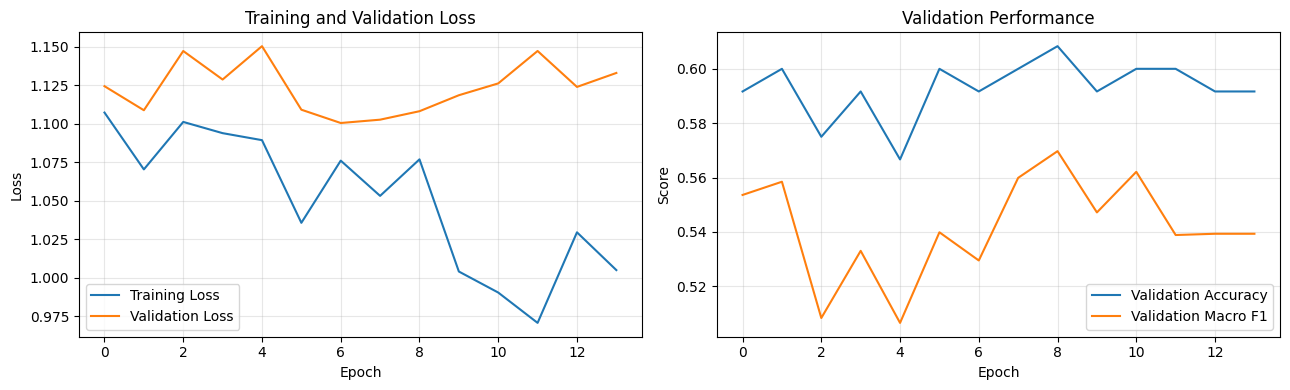

In [43]:

import matplotlib.pyplot as plt

history_df = pd.DataFrame(history)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history_df["train_loss"], label="Training Loss")
axes[0].plot(history_df["val_loss"], label="Validation Loss")
axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    history_df["val_accuracy"],
    label="Validation Accuracy"
)
axes[1].plot(
    history_df["val_macro_f1"],
    label="Validation Macro F1"
)
axes[1].set_title("Validation Performance")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    "/content/retinalens_models/training_curves.png",
    dpi=300
)
plt.show()


RETINALENS - FINAL TEST RESULTS
Accuracy:          0.5750
Macro Precision:   0.5442
Macro Recall:      0.5509
Macro F1 Score:    0.5176
Quadratic Kappa:   0.7289

CLASSIFICATION REPORT
               precision    recall  f1-score   support

        No DR       0.85      0.67      0.75       174
         Mild       0.26      0.70      0.38        46
     Moderate       0.52      0.27      0.36        92
       Severe       0.64      0.72      0.68        68
Proliferative       0.44      0.40      0.42        20

     accuracy                           0.57       400
    macro avg       0.54      0.55      0.52       400
 weighted avg       0.65      0.57      0.59       400



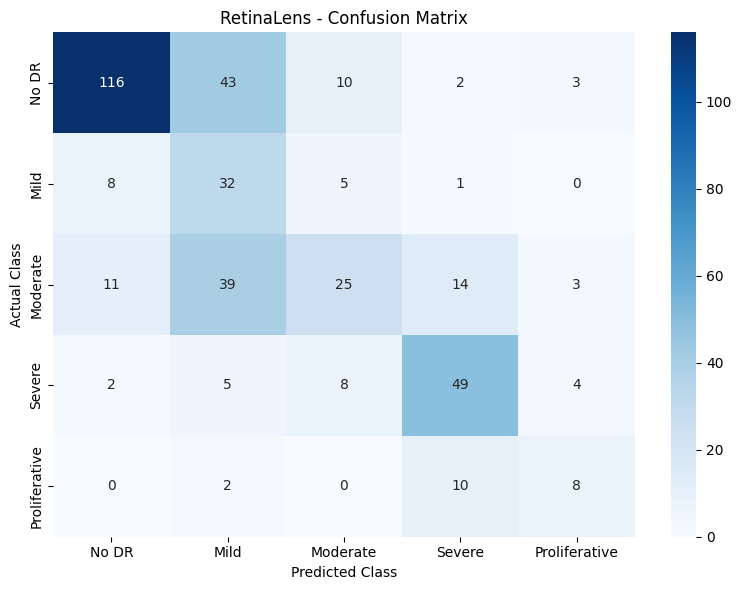

In [44]:

import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score
)

model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.view(-1).long().to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred,
    average="macro", zero_division=0
)

recall = recall_score(
    y_true, y_pred,
    average="macro", zero_division=0
)

macro_f1 = f1_score(
    y_true, y_pred,
    average="macro", zero_division=0
)

qwk = cohen_kappa_score(
    y_true, y_pred,
    weights="quadratic"
)

print("=" * 50)
print("RETINALENS - FINAL TEST RESULTS")
print("=" * 50)

print(f"Accuracy:          {accuracy:.4f}")
print(f"Macro Precision:   {precision:.4f}")
print(f"Macro Recall:      {recall:.4f}")
print(f"Macro F1 Score:    {macro_f1:.4f}")
print(f"Quadratic Kappa:   {qwk:.4f}")

print("\nCLASSIFICATION REPORT")

print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3, 4],
        target_names=[
            "No DR",
            "Mild",
            "Moderate",
            "Severe",
            "Proliferative"
        ],
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(
    y_true, y_pred,
    labels=[0, 1, 2, 3, 4]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "No DR", "Mild", "Moderate",
        "Severe", "Proliferative"
    ],
    yticklabels=[
        "No DR", "Mild", "Moderate",
        "Severe", "Proliferative"
    ]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("RetinaLens - Confusion Matrix")
plt.tight_layout()

plt.savefig(
    "/content/retinalens_models/confusion_matrix.png",
    dpi=300
)

plt.show()


Saving retinal_test_sample.jpg to retinal_test_sample (2).jpg

RETINALENS PREDICTION
-----------------------------------
Predicted Grade: 0
Severity: No DR

Class Probabilities:
No DR: 36.74%
Mild DR: 7.94%
Moderate DR: 13.03%
Severe DR: 20.99%
Proliferative DR: 21.31%


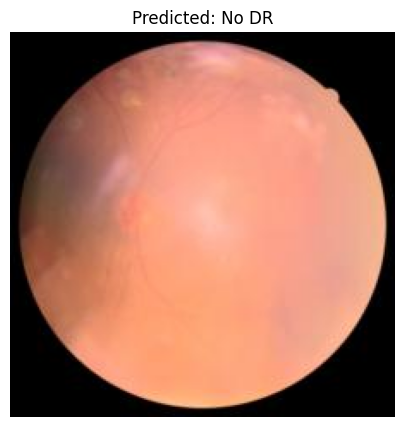

In [39]:

from PIL import Image
from google.colab import files
import torch.nn.functional as F

class_names = [
    "No DR",
    "Mild DR",
    "Moderate DR",
    "Severe DR",
    "Proliferative DR"
]

def predict_retina(image_path):

    image = Image.open(image_path).convert("RGB")

    input_tensor = eval_transform(image).unsqueeze(0)
    input_tensor = input_tensor.to(device)

    model.eval()

    with torch.no_grad():
        outputs = model(input_tensor)

        probabilities = F.softmax(
            outputs, dim=1
        )[0]

        predicted_class = probabilities.argmax().item()

    print("\nRETINALENS PREDICTION")
    print("-" * 35)

    print("Predicted Grade:", predicted_class)
    print("Severity:", class_names[predicted_class])

    print("\nClass Probabilities:")

    for i, probability in enumerate(probabilities):
        print(
            f"{class_names[i]}: "
            f"{probability.item() * 100:.2f}%"
        )

    plt.figure(figsize=(6, 5))
    plt.imshow(image)
    plt.title(
        f"Predicted: {class_names[predicted_class]}"
    )
    plt.axis("off")
    plt.show()

# Upload an image
uploaded = files.upload()

for filename in uploaded.keys():
    predict_retina(filename)


In [45]:

import json
import os

# Save model checkpoint with metadata
torch.save({
    "model_state_dict": model.state_dict(),
    "architecture": "MobileNetV2",
    "num_classes": 5,
    "class_names": class_names,
    "input_size": 224
}, "/content/retinalens_models/retinalens_final.pth")

# Save evaluation metrics
metrics = {
    "accuracy": float(accuracy),
    "precision_macro": float(precision),
    "recall_macro": float(recall),
    "f1_macro": float(macro_f1),
    "quadratic_weighted_kappa": float(qwk)
}

with open(
    "/content/retinalens_models/evaluation_metrics.json",
    "w"
) as f:
    json.dump(metrics, f, indent=4)

print("Final model and evaluation metrics saved!")


Final model and evaluation metrics saved!


In [46]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import cv2

from torchvision import transforms

In [47]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None

        self.forward_hook = target_layer.register_forward_hook(
            self.save_activation
        )

        self.backward_hook = target_layer.register_full_backward_hook(
            self.save_gradient
        )

    def save_activation(self, module, input, output):
        self.activations = output.detach()

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, input_tensor, class_index=None):
        self.model.zero_grad()

        output = self.model(input_tensor)

        if class_index is None:
            class_index = output.argmax(dim=1).item()

        score = output[:, class_index]
        score.backward()

        weights = self.gradients.mean(dim=(2, 3), keepdim=True)

        cam = (weights * self.activations).sum(dim=1)
        cam = F.relu(cam)

        cam = F.interpolate(
            cam.unsqueeze(1),
            size=(224, 224),
            mode="bilinear",
            align_corners=False
        )

        cam = cam.squeeze().cpu().numpy()

        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)

        return cam, output.detach()

    def remove_hooks(self):
        self.forward_hook.remove()
        self.backward_hook.remove()

In [49]:
# Ensure the best checkpoint is loaded
model.eval()

grad_cam = GradCAM(
    model=model,
    target_layer=model.features[-1]
)

# Select one test image
image_tensor, actual_label = test_dataset[0]

input_tensor = image_tensor.unsqueeze(0).to(device)

# Generate heatmap
heatmap, output = grad_cam.generate(input_tensor)

predicted_class = output.argmax(dim=1).item()
confidence = torch.softmax(output, dim=1)[0, predicted_class].item()

class_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative"
]
actual_label = int(np.asarray(actual_label).squeeze())

print("Actual Grade:", class_names[actual_label])
print("Predicted Grade:", class_names[predicted_class])
print("Confidence:", f"{confidence * 100:.2f}%")

Actual Grade: Moderate
Predicted Grade: No DR
Confidence: 64.87%


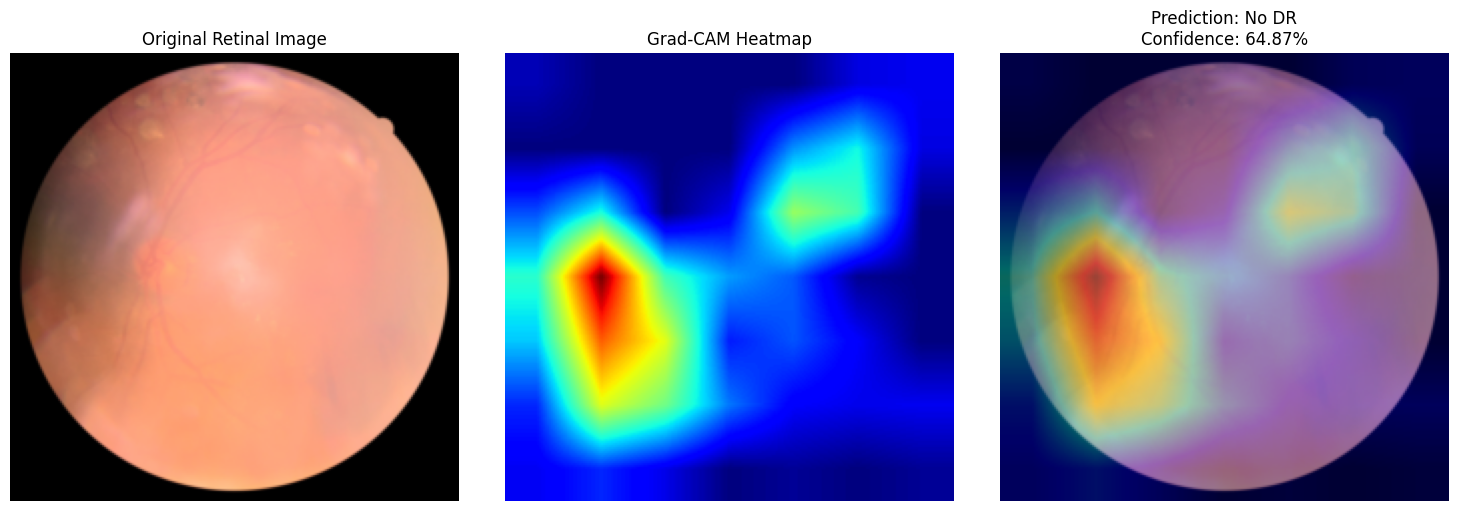

In [51]:
# Convert normalized tensor back to displayable image
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

original = image_tensor.permute(1, 2, 0).cpu().numpy()
original = np.clip(original * std + mean, 0, 1)

# Convert heatmap to color
heatmap_uint8 = np.uint8(255 * heatmap)
colored_heatmap = cv2.applyColorMap(
    heatmap_uint8,
    cv2.COLORMAP_JET
)
colored_heatmap = cv2.cvtColor(
    colored_heatmap,
    cv2.COLOR_BGR2RGB
)

# Overlay heatmap
overlay = (
    0.6 * original * 255 +
    0.4 * colored_heatmap
)

overlay = np.clip(overlay, 0, 255).astype(np.uint8)

# Display
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original)
plt.title("Original Retinal Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title(
    f"Prediction: {class_names[predicted_class]}\n"
    f"Confidence: {confidence * 100:.2f}%"
)
plt.axis("off")

plt.tight_layout()
plt.savefig(
    "/content/retinalens_gradcam.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()